```markdown
# Team 
- Daram Vishnuvardhan | CS24MTECH12002
- Madhan V | CS24MTECH11021
- Rushikeswar Reddy Payasam | CS24MTECH11018

```

# Implementing costsensitive logistic regression


## 1. Sigmoid Function

### Description
Implements the sigmoid (logistic) function, a fundamental component of logistic regression that maps any real number to the interval (0,1).

### Mathematical Definition
For any input $z$, the sigmoid function is defined as:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

In [10]:
import numpy as np



def sigmoid(z):
    """Compute the sigmoid of z."""
    return 1 / (1 + np.exp(-z))

def predict_prob(X, theta):
    """Predict probabilities for each sample."""
    return sigmoid(X.dot(theta))



## 2. Cost-Sensitive Logistic Cost Function

Computes the cost-sensitive logistic cost and its gradient.

The cost for each sample $i$ is given by:

$$cost_i = y_i[p_i \cdot C_{TP} + (1-p_i) \cdot c_{fn_i}] + (1-y_i)[p_i \cdot C_{FP} + (1-p_i) \cdot C_{TN}]$$


### Derivative Components

The derivative of the cost function has two main components:

1. **Derivative of cost with respect to probability ($\frac{\partial cost}{\partial p}$)**:
   $$\frac{\partial cost}{\partial p} = y_i(C_{TP} - c_{fn_i}) + (1-y_i)(C_{FP} - C_{TN})$$

2. **Derivative of sigmoid (probability) with respect to logit ($\frac{\partial p}{\partial z}$)**:
   $$\frac{\partial p}{\partial z} = p(1-p)$$

where:
- $y_i$ is the true label (0 or 1)
- $p$ is the predicted probability from sigmoid function
- $C_{TP}$ is the cost of true positives
- $C_{FP}$ is the cost of false positives
- $C_{TN}$ is the cost of true negatives
- $c_{fn_i}$ is the sample-specific cost of false negatives

### Parameters

| Parameter | Type | Description |
|-----------|------|-------------|
| `theta` | `(d,) numpy array` | Model parameters |
| `X` | `(n, d) numpy array` | Feature matrix |
| `y` | `(n,) numpy array` | Binary labels {0,1} |
| `c_tp` | `float` | Constant cost for true positives |
| `c_tn` | `float` | Constant cost for true negatives | 
| `c_fp` | `float` | Constant cost for false positives |
| `c_fn_array` | `(n,) numpy array` | Row-specific false negative cost for each sample |

### Returns

| Variable | Type | Description |
|----------|------|-------------|
| `J` | `float` | Average cost across samples |
| `grad` | `(d,) numpy array` | Gradient of the cost with respect to theta |

In [11]:
def cost_grad(theta, b, X, y, c_tp, c_tn, c_fp, c_fn_array):
    

    z = X.dot(theta) + b 
    p = sigmoid(z)        

  
    cost_per_sample = (
        y * (p * c_tp + (1 - p) * c_fn_array) +
        (1 - y) * (p * c_fp + (1 - p) * c_tn)
    )
    J = np.mean(cost_per_sample)

   
    dcost_dp = y * (c_tp - c_fn_array) + (1 - y) * (c_fp - c_tn)

    dp_dz = p * (1 - p)

    # For each sample i:
    # grad_theta_i = [ d(cost_i)/dp_i * dp_i/dz_i ] * X_i
    # grad_b_i     = [ d(cost_i)/dp_i * dp_i/dz_i ]
    # Then take the mean across samples.

    # Per-sample factor = d(cost_i)/dz_i = dcost_dp_i * dp_dz_i
    dcost_dz = dcost_dp * dp_dz  # shape: (n,)

    # ---------------------------
    # Gradient w.r.t. theta
    # shape of X is (n, d), dcost_dz is (n,), so we do a weighted sum across n
    grad_theta = X.T.dot(dcost_dz) / len(y)  # shape: (d,)

    # ---------------------------
    # Gradient w.r.t. bias b
    # Just the average of the per-sample partial derivative
    grad_b = np.mean(dcost_dz)  # scalar

    return J, grad_theta, grad_b

## 3. Cost-Sensitive Logistic Regression Training

### Function Description
`cost_sensitive_logistic_regression` implements batch gradient descent for training a cost-sensitive logistic regression model.

### Parameters

| Parameter | Type | Description |
|-----------|------|-------------|
| `X` | `(n, d) numpy array` | Feature matrix with n samples and d features |
| `y` | `(n,) numpy array` | Binary labels {0,1} |
| `alpha` | `float` | Learning rate (default: 0.01) |
| `num_iter` | `int` | Number of iterations (default: 1000) |

### Returns

| Variable | Type | Description |
|----------|------|-------------|
| `theta` | `(d,) numpy array` | Learned model parameters |
| `cost_history` | `list of float` | Cost values at each iteration |
| `bias` | `float` | bias taken in logistic regression |

### Algorithm
1. Initialize model parameters `theta` to zeros
2. For each iteration:
   - Compute cost and gradient using `cost_grad` function
   - Update parameters using gradient descent: θ = θ - α∇J
   - Store cost for monitoring
   - Print progress every 100 iterations



In [12]:
def cost_sensitive_logistic_regression(
    X, y,
    c_tp, c_tn, c_fp, c_fn_array,
    alpha=0.01,
    num_iter=1000
):
    

    n, d = X.shape
    theta = np.zeros(d)  # weights
    b = 0.0              # bias

    cost_history = []

    for i in range(num_iter):
        J, grad_theta, grad_b = cost_grad(theta, b, X, y, c_tp, c_tn, c_fp, c_fn_array)

        # Update parameters
        theta -= alpha * grad_theta
        b     -= alpha * grad_b

        cost_history.append(J)

        if (i + 1) % 100 == 0:
            print(f"Iteration {i+1}, Cost: {J:.4f}")

    return theta, b, cost_history

## 4. COMPUTE COST ON A GIVEN DATASET


In [13]:

def compute_cost(X, y, c_tp, c_tn, c_fp, c_fn_array, theta, b):
    """
    Compute the average cost for a dataset X, y with parameters theta.
    """
    J, *_ = cost_grad(theta,b, X, y, c_tp, c_tn, c_fp, c_fn_array)
    return J

## Main Script Implementation

### Overview
This script implements a cost-sensitive logistic regression model for binary classification with varying false negative costs per sample.

### Data Processing Steps

#### 1. Data Loading
```python
df = pd.read_csv("costsensitiveregression.csv")
```
- Reads CSV file with columns:
  - Features: YesCount, ATPM, PFD, PFG, SFD, SFG, WP, WS, AH, AN
  - Target: Status
  - Cost: FNC (False Negative Cost)

#### 2. Feature and Target Definition
- **Features (X)**: 10 numerical columns
- **Target (y)**: Binary Status column (converted to int)
- **FN Cost**: Sample-specific false negative costs

#### 3. Data Splitting
```python
train_test_split(test_size=0.2, random_state=42)
```
- 80% training data
- 20% test data
- Splits maintain alignment between features, targets, and FN costs

#### 4. Cost Matrix Definition
| Cost Type | Value |
|-----------|-------|
| True Positive (C_TP) | 3.0 |
| False Positive (C_FP) | 3.0 |
| True Negative (C_TN) | 0.0 |
| False Negative | Variable per sample |

#### 5. Model Training
```python
cost_sensitive_logistic_regression(
    alpha=0.01,
    num_iter=1000
)
```

#### 6. Evaluation
- Computes average cost on both training and test sets
- Generates predictions:
  - Probability scores
  - Binary labels (threshold = 0.5)

### Output
- Learned model parameters
- Training history
- Average costs on train/test sets
- Sample predictions with probabilities and labels

In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split


if __name__ == "__main__":
    # A) READ  CSV

    df = pd.read_csv("costsensitiveregression.csv")

    print("Columns found:", df.columns.to_list())

    # B) DEFINE FEATURES, TARGET, AND FN COST
    feature_cols = [
        "YesCount", "ATPM", "PFD", "PFG",
        "SFD", "SFG", "WP", "WS", "AH", "AN"
    ]
    X_full = df[feature_cols].values               # shape: (n, 10)
    y_full = df["Status"].values.astype(int)       # shape: (n,)
    fn_cost_array = df["FNC"].values               # shape: (n,)

    # C) SPLIT INTO TRAIN/TEST
    X_train, X_test, y_train, y_test, fn_train, fn_test = train_test_split(
        X_full, y_full, fn_cost_array, test_size=0.2, random_state=42
    )

    # D) DEFINE COST CONSTANTS (true positive, true negative, false positive)
    C_TP = 3.0
    C_FP = 3.0
    C_TN = 0.0

    actual_tp_cost_train = np.full(y_train.shape, C_TP)
    actual_tn_cost_train = np.full(y_train.shape, C_TN)
    actual_fp_cost_train = np.full(y_train.shape, C_FP)
    actual_fn_cost_train = fn_train

    actual_tp_cost_test = np.full(y_test.shape, C_TP)
    actual_tn_cost_test = np.full(y_test.shape, C_TN)
    actual_fp_cost_test = np.full(y_test.shape, C_FP)
    actual_fn_cost_test = fn_test
    
    

    # E) TRAIN THE MODEL
    theta, bias,cost_history_train = cost_sensitive_logistic_regression(
        X_train, y_train,
        c_tp=C_TP, c_tn=C_TN, c_fp=C_FP, c_fn_array=fn_train,
        alpha=0.01,
        num_iter=1000
    )

    print("\n=== TRAINING COMPLETE ===")
    print("Learned parameters (theta):", theta)
    print("Learned bias:", bias)
    print("Final training cost:", cost_history_train[-1])
    # # applying threshold on labels
    # y_train = predict_label(X_train, theta, threshold=0.1)
    # y_test = predict_label(X_test, theta, threshold=0.1)


    # F) EVALUATE COST ON TRAIN & TEST
    train_cost = compute_cost(X_train, y_train, C_TP, C_TN, C_FP, fn_train, theta,bias)
    test_cost  = compute_cost(X_test,  y_test,  C_TP, C_TN, C_FP, fn_test,  theta,bias)

    print(f"\nAverage TRAINING cost: {train_cost:.4f}")
    print(f"Average TEST     cost: {test_cost:.4f}")

    # G) EXAMPLE PREDICTIONS
    y_prob_test = predict_prob(X_test, theta)


    print("\nSample predictions on test set:")
    print("Probabilities:", y_prob_test[:10])


Columns found: ['NotCount', 'YesCount', 'ATPM', 'PFD', 'PFG', 'SFD', 'SFG', 'WP', 'WS', 'AH', 'AN', 'Status', 'FNC']
Iteration 100, Cost: 3.6258
Iteration 200, Cost: 3.3349
Iteration 300, Cost: 3.2309
Iteration 400, Cost: 3.1769
Iteration 500, Cost: 3.1438
Iteration 600, Cost: 3.1213
Iteration 700, Cost: 3.1050
Iteration 800, Cost: 3.0926
Iteration 900, Cost: 3.0829
Iteration 1000, Cost: 3.0751

=== TRAINING COMPLETE ===
Learned parameters (theta): [1.98144037 2.31874924 0.1331477  0.13046869 0.48174528 0.0149872
 0.84531582 1.81583284 0.48569089 0.12846872]
Learned bias: 3.4714427313818317
Final training cost: 3.0750535972057893

Average TRAINING cost: 3.0750
Average TEST     cost: 3.0854

Sample predictions on test set:
Probabilities: [1.  1.  1.  1.  1.  1.  1.  1.  1.  0.5]


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

thresholds = np.linspace(0.0, 0.99, 100)
avg_costs_simple_lr_test = []
avg_costs_cost_sensitive_lr_test = []
avg_costs_simple_lr_train = []
avg_costs_cost_sensitive_lr_train = []
y_probs_simplelogistic = model.predict_proba(X_test)[:, 1]
y_probs_simplelogistic_train = model.predict_proba(X_train)[:, 1]
y_probs_cost_sensitive_LR = predict_prob(X_test, theta)
y_probs_cost_sensitive_LR_train = predict_prob(X_train, theta)



for thresh in thresholds:

    # 1) Simple Logistic Test

    y_pred_simple_test = (y_probs_simplelogistic >= thresh).astype(int)
    
    # Create masks
    tp_mask_test = (y_test == 1) & (y_pred_simple_test == 1)
    tn_mask_test = (y_test == 0) & (y_pred_simple_test == 0)
    fp_mask_test = (y_test == 0) & (y_pred_simple_test == 1)
    fn_mask_test = (y_test == 1) & (y_pred_simple_test == 0)
    
    # Build cost vector for test set
    cost_vec_test = np.zeros_like(y_test, dtype=float)
    cost_vec_test[tp_mask_test] = actual_tp_cost_test[tp_mask_test]
    cost_vec_test[tn_mask_test] = actual_tn_cost_test[tn_mask_test]
    cost_vec_test[fp_mask_test] = actual_fp_cost_test[fp_mask_test]
    cost_vec_test[fn_mask_test] = actual_fn_cost_test[fn_mask_test]
    
    # Compute average test cost at this threshold
    avg_test_cost_simple = cost_vec_test.mean()
    avg_costs_simple_lr_test.append(avg_test_cost_simple)
    

    # 2) Simple Logistic Train

    y_pred_simple_train = (y_probs_simplelogistic_train >= thresh).astype(int)
    
    # Create masks
    tp_mask_train = (y_train == 1) & (y_pred_simple_train == 1)
    tn_mask_train = (y_train == 0) & (y_pred_simple_train == 0)
    fp_mask_train = (y_train == 0) & (y_pred_simple_train == 1)
    fn_mask_train = (y_train == 1) & (y_pred_simple_train == 0)
    
    # Build cost vector for train set
    cost_vec_train = np.zeros_like(y_train, dtype=float)
    cost_vec_train[tp_mask_train] = actual_tp_cost_train[tp_mask_train]
    cost_vec_train[tn_mask_train] = actual_tn_cost_train[tn_mask_train]
    cost_vec_train[fp_mask_train] = actual_fp_cost_train[fp_mask_train]
    cost_vec_train[fn_mask_train] = actual_fn_cost_train[fn_mask_train]
    
    # Compute average train cost at this threshold
    avg_train_cost_simple = cost_vec_train.mean()
    avg_costs_simple_lr_train.append(avg_train_cost_simple)
    

    # 3) Cost-Sensitive LR Test

    y_pred_costsens_test = (y_probs_cost_sensitive_LR >= thresh).astype(int)
    
    tp_mask_test_cs = (y_test == 1) & (y_pred_costsens_test == 1)
    tn_mask_test_cs = (y_test == 0) & (y_pred_costsens_test == 0)
    fp_mask_test_cs = (y_test == 0) & (y_pred_costsens_test == 1)
    fn_mask_test_cs = (y_test == 1) & (y_pred_costsens_test == 0)
    
    cost_vec_test_cs = np.zeros_like(y_test, dtype=float)
    cost_vec_test_cs[tp_mask_test_cs] = actual_tp_cost_test[tp_mask_test_cs]
    cost_vec_test_cs[tn_mask_test_cs] = actual_tn_cost_test[tn_mask_test_cs]
    cost_vec_test_cs[fp_mask_test_cs] = actual_fp_cost_test[fp_mask_test_cs]
    cost_vec_test_cs[fn_mask_test_cs] = actual_fn_cost_test[fn_mask_test_cs]
    
    avg_test_cost_cs = cost_vec_test_cs.mean()
    avg_costs_cost_sensitive_lr_test.append(avg_test_cost_cs)
    

    # 4) Cost-Sensitive LR Train

    y_pred_costsens_train = (y_probs_cost_sensitive_LR_train >= thresh).astype(int)
    
    tp_mask_train_cs = (y_train == 1) & (y_pred_costsens_train == 1)
    tn_mask_train_cs = (y_train == 0) & (y_pred_costsens_train == 0)
    fp_mask_train_cs = (y_train == 0) & (y_pred_costsens_train == 1)
    fn_mask_train_cs = (y_train == 1) & (y_pred_costsens_train == 0)
    
    cost_vec_train_cs = np.zeros_like(y_train, dtype=float)
    cost_vec_train_cs[tp_mask_train_cs] = actual_tp_cost_train[tp_mask_train_cs]
    cost_vec_train_cs[tn_mask_train_cs] = actual_tn_cost_train[tn_mask_train_cs]
    cost_vec_train_cs[fp_mask_train_cs] = actual_fp_cost_train[fp_mask_train_cs]
    cost_vec_train_cs[fn_mask_train_cs] = actual_fn_cost_train[fn_mask_train_cs]
    
    avg_train_cost_cs = cost_vec_train_cs.mean()
    avg_costs_cost_sensitive_lr_train.append(avg_train_cost_cs)

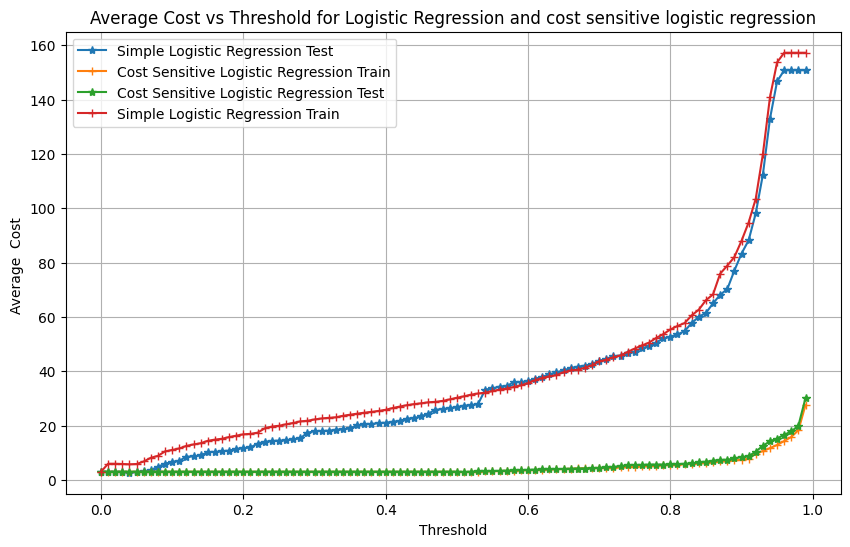

In [16]:
plt.figure(figsize=(10,6))
plt.plot(thresholds, avg_costs_simple_lr_test, marker='*',label='Simple Logistic Regression Test')
plt.plot(thresholds, avg_costs_cost_sensitive_lr_train, marker='+',label='Cost Sensitive Logistic Regression Train')
plt.plot(thresholds, avg_costs_cost_sensitive_lr_test, marker='*',label='Cost Sensitive Logistic Regression Test')
plt.plot(thresholds, avg_costs_simple_lr_train, marker='+',label='Simple Logistic Regression Train')
plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Average  Cost ')
plt.title('Average Cost vs Threshold for Logistic Regression and cost sensitive logistic regression')
plt.grid(True)
plt.show()

<Figure size 640x480 with 0 Axes>

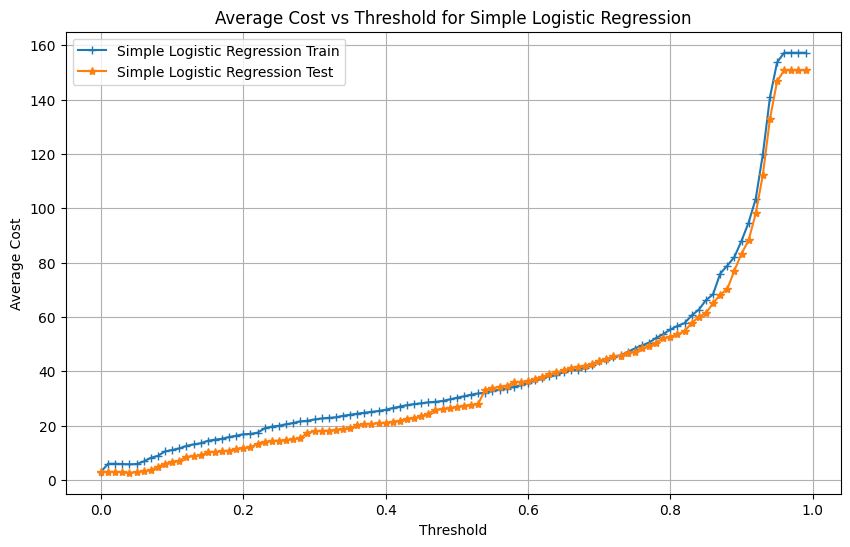

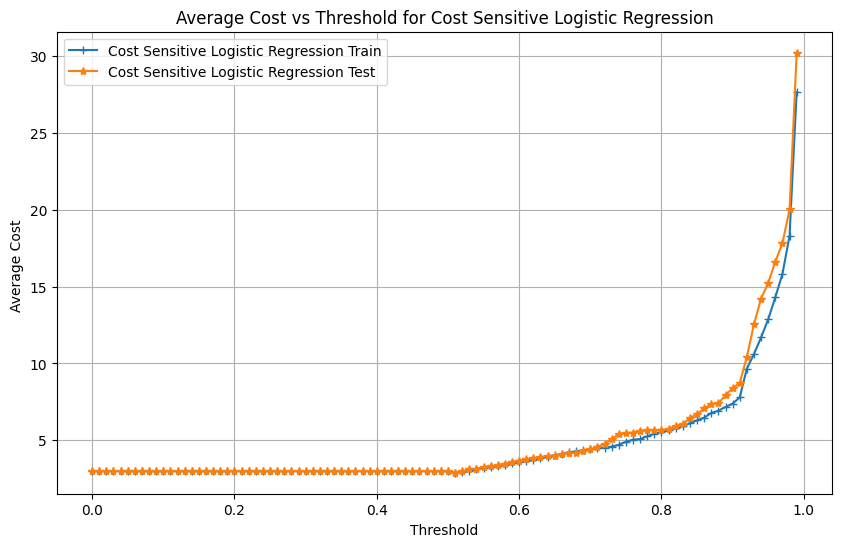

In [ ]:
plt.clf()

# First figure: Simple Logistic Regression
plt.figure(figsize=(10,6))
plt.plot(thresholds, avg_costs_simple_lr_train, marker='+', label='Simple Logistic Regression Train')
plt.plot(thresholds, avg_costs_simple_lr_test, marker='*', label='Simple Logistic Regression Test')
plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Average Cost')
plt.title('Average Cost vs Threshold for Simple Logistic Regression')
plt.grid(True)
plt.show()

# Second figure: Cost Sensitive Logistic Regression
plt.figure(figsize=(10,6))
plt.plot(thresholds, avg_costs_cost_sensitive_lr_train, marker='+', label='Cost Sensitive Logistic Regression Train')
plt.plot(thresholds, avg_costs_cost_sensitive_lr_test, marker='*', label='Cost Sensitive Logistic Regression Test')
plt.legend()
plt.xlabel('Threshold')
plt.ylabel('Average Cost ')
plt.title('Average Cost vs Threshold for Cost Sensitive Logistic Regression')
plt.grid(True)
plt.show()